In [2]:
import pandas as pd
import numpy as np
import cv2
import os
from pathlib import Path
from PIL import Image

IMG_SIZE = 224
IMG_EXT = ('.png', '.jpeg', '.jpg', '.bmp')
SEED = 42

ROOT = Path.cwd().parent
RAW_DIR = ROOT / 'data' / 'raw'
SPLIT_DIR = ROOT / 'data' / 'split'

df = pd.DataFrame()
print(np.__version__)
print(Path.cwd().parent)

2.5.4
c:\BrainScan_V2


## 1. Chargement et prétraitement du dataset

### 1.1 Exploration des classes

In [3]:
classes = sorted(c for c in RAW_DIR.iterdir() if c.is_dir())
classes
for c in classes:
    count = len(list(c.iterdir()))
    print(f"{c.name}: {count}")

# for class_path in classes:
#     print(class_path)


glioma: 1621
meningioma: 1645
notumor: 2000
pituitary: 1757


### 1.2 Contrôle qualité



In [4]:
valid, invalid = [], []

for class_Path in classes:

    for file in class_Path.iterdir():
        if file.suffix.lower() not in IMG_EXT :
            invalid.append((str(file), "bad extension"))
            continue
        try:
            img = cv2.imread(file)
            valid.append((str(file), class_Path.name))
        except Exception as e:
            invalid.append((str(file), f"corrupted: {e}"))

df = pd.DataFrame(valid, columns=['path', 'label'])
print(f"Valid images:   {len(df)}")
print(f"Invalid images: {len(invalid)}")         
df

Valid images:   7023
Invalid images: 0


,path,label
0,c:\BrainScan_V2\data\raw\glioma\Te-glTr_0000.jpg,glioma
1,c:\BrainScan_V2\data\raw\glioma\Te-glTr_0001.jpg,glioma
2,c:\BrainScan_V2\data\raw\glioma\Te-glTr_0002.jpg,glioma
3,c:\BrainScan_V2\data\raw\glioma\Te-glTr_0003.jpg,glioma
4,c:\BrainScan_V2\data\raw\glioma\Te-glTr_0004.jpg,glioma
...,...,...
7018,c:\BrainScan_V2\data\raw\pituitary\Tr-pi_1452.jpg,pituitary
7019,c:\BrainScan_V2\data\raw\pituitary\Tr-pi_1453.jpg,pituitary
7020,c:\BrainScan_V2\data\raw\pituitary\Tr-pi_1454.jpg,pituitary
7021,c:\BrainScan_V2\data\raw\pituitary\Tr-pi_1455.jpg,pituitary


Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
label
notumor       2000
pituitary     1757
meningioma    1645
glioma        1621
Name: count, dtype: int64


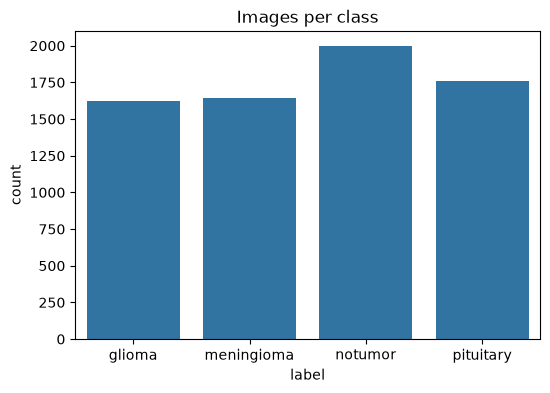

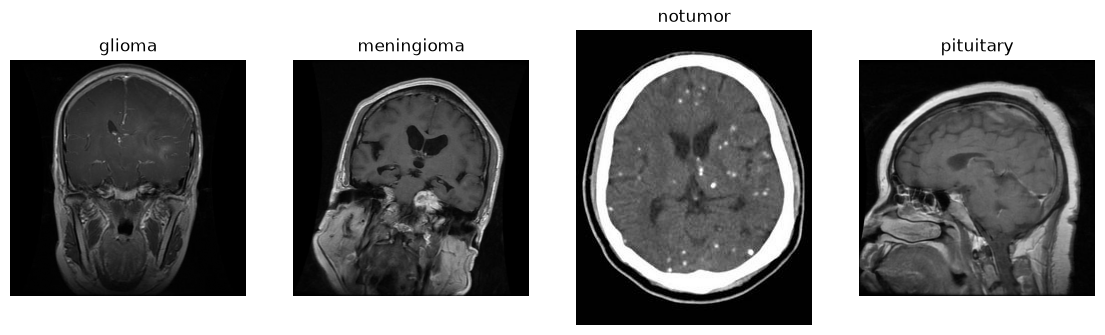

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. classes = folder names
classes = sorted(df["label"].unique())
print("Classes:", classes)
print(df["label"].value_counts())

# 2. countplot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="label", order=classes)
plt.title("Images per class")
plt.show()

# 3. one sample per class
fig, axes = plt.subplots(1, len(classes), figsize=(14, 8))
for ax, cls in zip(axes, classes):
    sample_path = df[df['label'] == cls].sample(1)['path'].values[0]
    ax.imshow(Image.open(sample_path), cmap='gray')
    ax.set_title(cls)
    ax.axis("off")
    

plt.show()

Train: 4916
valid: 1053
test: 1054


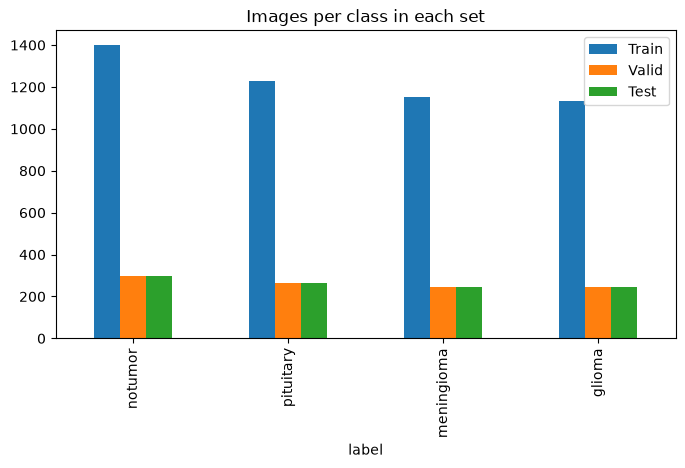

In [6]:
from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=SEED
)

valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)
print('Train:', len(train_df))
print('valid:', len(valid_df))
print('test:', len(test_df))

counts = pd.DataFrame({
    'Train':train_df['label'].value_counts(),
    'Valid':valid_df['label'].value_counts(),
    'Test':test_df['label'].value_counts()
})
counts

counts.plot(kind='bar', figsize=(8, 4), title="Images per class in each set")
plt.show()

In [7]:
import shutil


def copy_files(dataframe, set_name):
    for _, row in dataframe.iterrows():
        dest = SPLIT_DIR / set_name / row["label"]
        dest.mkdir(parents=True, exist_ok=True)
        shutil.copy(row["path"], dest / Path(row["path"]).name)

copy_files(train_df, "train")
copy_files(valid_df, "val")
copy_files(test_df, "test")

print("Copy done")

Copy done


In [8]:
def blur(img):
    return cv2.GaussianBlur(img, (5, 5), 0)

def add_noise(img):
    noise = np.random.normal(0, 15, img.shape)
    noisy = img.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)

def flip(img):
    return cv2.flip(img, 1)

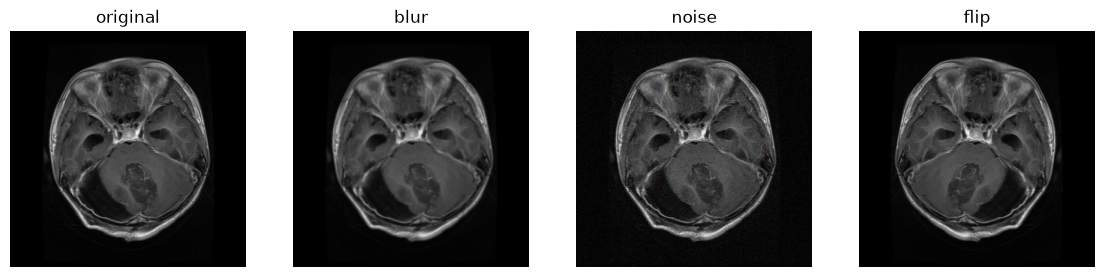

In [9]:
import matplotlib.pyplot as plt

sample = next((SPLIT_DIR / "train" / "glioma").glob("*"))
img = cv2.imread(str(sample))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV reads BGR, matplotlib expects RGB

versions = {"original": img, "blur": blur(img), "noise": add_noise(img), "flip": flip(img)}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, im) in zip(axes, versions.items()):
    ax.imshow(im)
    ax.set_title(name)
    ax.axis("off")
plt.show()

In [19]:
import random

random.seed(SEED)
np.random.seed(SEED)

augmentations = {'blur':blur, 'flip':flip, 'noise':add_noise}

TRAIN_DIR = SPLIT_DIR / 'train'

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
classes
target = max(class_counts.values())
target
print("Before:", class_counts, "-> target:", target)

for class_name, count in class_counts.items():
    class_dir = TRAIN_DIR / class_name
    originals = list(class_dir.glob('*'))
    n_missing = target - count

    for i in range(n_missing):
        src = random.choice(originals)
        aug_name, aug_func = random.choice(list(augmentations.items()))

        img = cv2.imread(str(src))
        new_img = aug_func(img)

        new_path = class_dir / f"aug_{i}_{aug_name}_{src.name}"
        cv2.imwrite(str(new_path), new_img)

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
class_counts


Before: {'glioma': 1135, 'meningioma': 1151, 'notumor': 1400, 'pituitary': 1230} -> target: 1400


{'glioma': 1400, 'meningioma': 1400, 'notumor': 1400, 'pituitary': 1400}